# 🐍🪜 Snakes & Ladders — ANN Win-Predictor + Playable Game

**What this notebook does**
1. Builds a Snakes & Ladders **CSV dataset** (5,000 simulated games) and loads it with pandas
2. Trains an **Artificial Neural Network (ANN)** with Keras to predict: *"from this board state, will the player about to roll go on to win?"*
3. Evaluates it: **accuracy, precision, recall, F1, ROC-AUC, confusion matrix**, training curves
4. Lets you **play** against the computer — the ANN shows a live win-probability after every move

> Run the cells top to bottom (Runtime ▸ Run all).

## 1. Setup

In [ ]:
import numpy as np, pandas as pd, random, os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, roc_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Board definition
Standard 10×10 board (100 squares). Rules: roll one die, land on a ladder base → climb, land on a snake head → slide. You must not overshoot 100 (if the roll is too big you stay put). First to 100 wins.

In [ ]:
BOARD_SIZE = 100
LADDERS = {1:38, 4:14, 9:31, 21:42, 28:84, 36:44, 51:67, 71:91, 80:100}
SNAKES  = {16:6, 47:26, 49:11, 56:53, 62:19, 64:60, 87:24, 93:73, 95:75, 98:78}
JUMPS = {**LADDERS, **SNAKES}

def move(pos, dice):
    new = pos + dice
    if new > BOARD_SIZE:          # overshoot -> stay
        return pos
    return JUMPS.get(new, new)

## 3. Dataset (CSV)
No Kaggle download needed. This cell builds the dataset itself: it plays 5,000 random 2-player games and logs the board state **before every roll**. Each row is one turn, saved to `snake_ladder_dataset.csv`.

| column | meaning |
|---|---|
| `game_id` | which game the row belongs to |
| `turn` | turn number within the game (per player) |
| `my_pos`, `opp_pos` | positions of the player about to roll / the opponent |
| `dice` | the die value that player then rolled |
| `mover_wins` | **label** – 1 if the player about to roll eventually won that game |

If you already have a CSV with these columns, upload it to Colab as `snake_ladder_dataset.csv` and it will be used instead.

In [ ]:
CSV_PATH = "/content/snake_ladder_dataset.csv"

def simulate_dataset(n_games=5000):
    rows = []
    for g in range(n_games):
        pos = [0, 0]; player = 0; turn = [0, 0]; history = []
        while True:
            dice = random.randint(1, 6)
            history.append((g, turn[player], pos[player], pos[1-player], dice, player))
            turn[player] += 1
            pos[player] = move(pos[player], dice)
            if pos[player] == BOARD_SIZE:
                winner = player; break
            player = 1 - player
        for (gid, t, me, opp, d, p) in history:
            rows.append((gid, t, me, opp, d, int(p == winner)))
    return pd.DataFrame(rows, columns=["game_id", "turn", "my_pos", "opp_pos", "dice", "mover_wins"])

if os.path.exists(CSV_PATH):
    print("Found", CSV_PATH, "- loading it")
else:
    print("No CSV found - generating one...")
    simulate_dataset().to_csv(CSV_PATH, index=False)
    print("Saved", CSV_PATH)

df = pd.read_csv(CSV_PATH)       # <- the model always trains from the CSV
print(df.shape)
df.head()

Found /content/snake_ladder_dataset.csv - loading it
(262124, 6)


,game_id,turn,my_pos,opp_pos,dice,mover_wins
0,0,0,0,0,5,1
1,0,0,0,5,3,0
2,0,1,5,3,4,1
3,0,1,3,31,6,0
4,0,2,31,31,5,1


In [ ]:
print(df["mover_wins"].value_counts(normalize=True).rename("class balance"))
df.describe().T

mover_wins
1    0.504883
0    0.495117
Name: class balance, dtype: float64


,count,mean,std,min,25%,50%,75%,max
game_id,262124.0,2478.546951,1439.728746,0.0,1232.0,2458.0,3727.0,4999.0
turn,262124.0,16.325518,14.197796,0.0,6.0,13.0,23.0,134.0
my_pos,262124.0,44.955582,28.706583,0.0,23.0,41.0,72.0,99.0
opp_pos,262124.0,46.046848,28.298452,0.0,24.0,42.0,73.0,99.0
dice,262124.0,3.504570,1.708922,1.0,2.0,4.0,5.0,6.0
mover_wins,262124.0,0.504883,0.499977,0.0,0.0,1.0,1.0,1.0


## 4. Features & train/test split
Features: my position, opponent position, and their difference (all scaled to 0–1).
We split **by game** (not by row) so states from one game never appear in both train and test — otherwise the test score would be inflated.

In [ ]:
def make_features(my, opp):
    my = np.asarray(my, dtype="float32"); opp = np.asarray(opp, dtype="float32")
    return np.stack([my/BOARD_SIZE, opp/BOARD_SIZE, (my-opp)/BOARD_SIZE], axis=1)

X = make_features(df.my_pos, df.opp_pos)
y = df.mover_wins.values.astype("float32")

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(X, y, groups=df.game_id))
X_train_full, y_train_full = X[tr_idx], y[tr_idx]
X_test, y_test = X[te_idx], y[te_idx]

# validation carved out of the training games
g_train = df.game_id.values[tr_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
a, b = next(gss2.split(X_train_full, y_train_full, groups=g_train))
X_train, y_train = X_train_full[a], y_train_full[a]
X_val,   y_val   = X_train_full[b], y_train_full[b]

print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)

train (177066, 3) | val (31434, 3) | test (53624, 3)


## 5. Build the ANN

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(3,)),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
], name="snakes_ladders_ann")

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
model.summary()

Model: "snakes_ladders_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,785 (26.50 KB)

 Trainable params: 6,657 (26.00 KB)

 Non-trainable params: 128 (512.00 B)

## 6. Train

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=40, batch_size=512, callbacks=callbacks, verbose=2)

Epoch 1/40
346/346 - 4s - 12ms/step - accuracy: 0.6130 - auc: 0.6688 - loss: 0.6457 - val_accuracy: 0.6054 - val_auc: 0.6714 - val_loss: 0.6655 - learning_rate: 0.0010
Epoch 2/40
346/346 - 2s - 5ms/step - accuracy: 0.6179 - auc: 0.6757 - loss: 0.6409 - val_accuracy: 0.6093 - val_auc: 0.6704 - val_loss: 0.6457 - learning_rate: 0.0010
Epoch 3/40
346/346 - 2s - 6ms/step - accuracy: 0.6186 - auc: 0.6765 - loss: 0.6405 - val_accuracy: 0.6106 - val_auc: 0.6709 - val_loss: 0.6438 - learning_rate: 0.0010
Epoch 4/40
346/346 - 3s - 9ms/step - accuracy: 0.6186 - auc: 0.6772 - loss: 0.6399 - val_accuracy: 0.6126 - val_auc: 0.6717 - val_loss: 0.6434 - learning_rate: 0.0010
Epoch 5/40
346/346 - 2s - 7ms/step - accuracy: 0.6190 - auc: 0.6776 - loss: 0.6396 - val_accuracy: 0.6125 - val_auc: 0.6718 - val_loss: 0.6434 - learning_rate: 0.0010
Epoch 6/40
346/346 - 2s - 5ms/step - accuracy: 0.6187 - auc: 0.6775 - loss: 0.6395 - val_accuracy: 0.6135 - val_auc: 0.6718 - val_loss: 0.6434 - learning_rate: 0.00

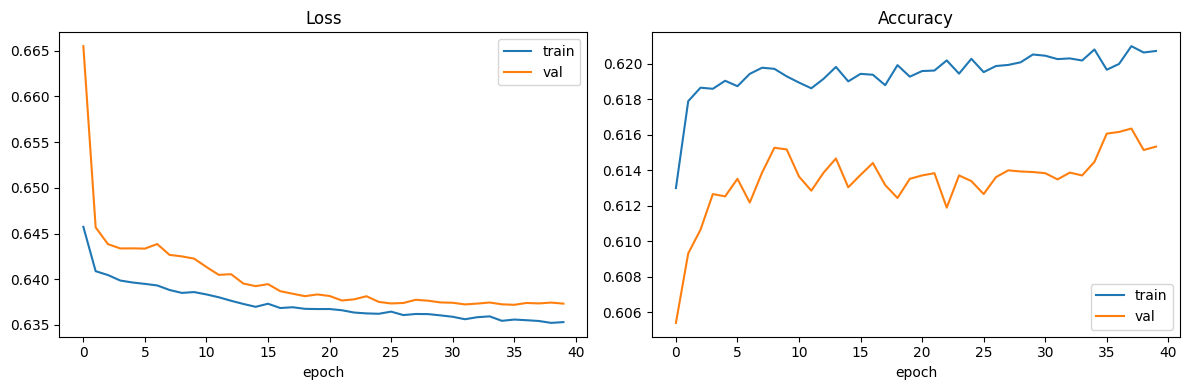

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Evaluation on the held-out test set

In [ ]:
y_prob = model.predict(X_test, batch_size=2048, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

metrics = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1 score":  f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_prob),
}
pd.DataFrame(metrics, index=["ANN (test set)"]).T.round(4)

,ANN (test set)
Accuracy,0.6128
Precision,0.6142
Recall,0.6264
F1 score,0.6202
ROC-AUC,0.6752


              precision    recall  f1-score   support

       Loses     0.6112    0.5989    0.6050     26553
        Wins     0.6142    0.6264    0.6202     27071

    accuracy                         0.6128     53624
   macro avg     0.6127    0.6126    0.6126     53624
weighted avg     0.6127    0.6128    0.6127     53624



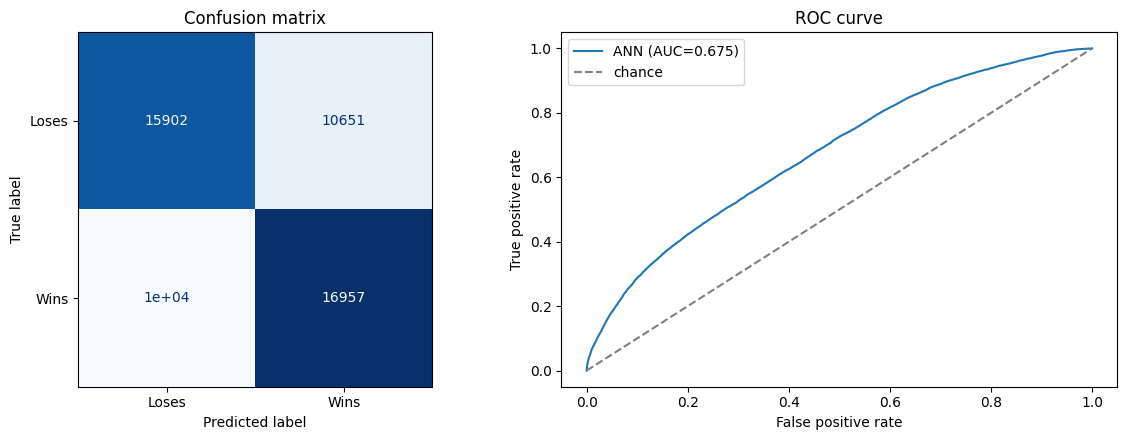

In [ ]:
print(classification_report(y_test, y_pred, target_names=["Loses", "Wins"], digits=4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Loses", "Wins"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix")
fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, label=f"ANN (AUC={metrics['ROC-AUC']:.3f})"); ax[1].plot([0,1],[0,1],"--",c="gray",label="chance")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].set_title("ROC curve"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Baseline: "whoever is further ahead will win" — does the ANN beat a simple rule?
base_pred = (df.my_pos.values[te_idx] >= df.opp_pos.values[te_idx]).astype(int)
cmp = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, base_pred), metrics["Accuracy"]],
    "F1":       [f1_score(y_test, base_pred),       metrics["F1 score"]],
}, index=["Baseline (further ahead wins)", "ANN"]).round(4)
cmp

,Accuracy,F1
Baseline (further ahead wins),0.6104,0.6102
ANN,0.6128,0.6202


**How to read these numbers.** Snakes & Ladders is a pure-luck game, so even a perfect model can't predict the winner with certainty — every roll is random. The realistic goal is a *well-calibrated win probability*. The ANN can learn what a square is really worth (e.g. square 79 is great because 80 is a ladder to 100, while 94 is risky because of the snakes at 95/98), which a simple "who's ahead" rule misses. Compare the ANN row with the baseline row above to see how much it adds.

## 8. Save the model

In [ ]:
model.save("snakes_ladders_ann.keras")
print("saved -> snakes_ladders_ann.keras")

saved -> snakes_ladders_ann.keras


## 9. 🎮 Play the game!
You are 🔵 (blue), the computer is 🔴 (red). Press **Roll dice**: you'll see an animated die for your roll, the token walks across the board, then the computer rolls its own die. Ladders and snakes are drawn on the board, and the trained **ANN shows each side's chance of winning** after every move.

In [ ]:
import ipywidgets as widgets
import time, math
from IPython.display import display, HTML

def win_prob(my, opp):                  # ANN's estimate that the player about to roll wins
    x = make_features([my], [opp])
    return float(model(x, training=False).numpy()[0, 0])

# ---------- look & feel ----------
CELL = 54
W = CELL * 10
H = CELL * 10 + 44                      # extra strip under the board for the START area
PALETTE = ["#ffd6e0", "#ffe8b3", "#d4f1c5", "#cfe8ff", "#e5d4ff"]
SNAKE_COLORS = ["#2e9d4f", "#d9480f", "#7048e8", "#1c7ed6", "#c2255c",
                "#e8a317", "#0ca678", "#e03131", "#5f3dc4", "#2b8a3e"]
YOU_COLOR, CPU_COLOR = "#1971c2", "#e03131"

def cell_number(r, c):                  # r=0 is the bottom row (zig-zag numbering)
    return r*10 + (c+1) if r % 2 == 0 else r*10 + (10-c)

def xy(n):                              # centre of square n in SVG pixels
    if n == 0:
        return (CELL*1.5, CELL*10 + 24)
    r, i = (n-1)//10, (n-1) % 10
    c = i if r % 2 == 0 else 9 - i
    return (c*CELL + CELL/2, (9-r)*CELL + CELL/2)

def ladder_svg(a, b):
    x1, y1 = xy(a); x2, y2 = xy(b)
    dx, dy = x2-x1, y2-y1
    L = math.hypot(dx, dy); ux, uy = dx/L, dy/L; px, py = -uy, ux
    w, s = 8, ''
    for k in range(1, int(L // 15) + 1):                       # rungs
        cx, cy = x1 + ux*k*15, y1 + uy*k*15
        s += (f"<line x1='{cx+px*w:.1f}' y1='{cy+py*w:.1f}' x2='{cx-px*w:.1f}' y2='{cy-py*w:.1f}' "
              f"stroke='#c07a3a' stroke-width='4' stroke-linecap='round'/>")
    for sg in (1, -1):                                          # side rails
        s += (f"<line x1='{x1+px*w*sg:.1f}' y1='{y1+py*w*sg:.1f}' x2='{x2+px*w*sg:.1f}' y2='{y2+py*w*sg:.1f}' "
              f"stroke='#7a4a1d' stroke-width='4.5' stroke-linecap='round'/>")
    return s

def snake_svg(head, tail, color):
    x1, y1 = xy(head); x2, y2 = xy(tail)
    dx, dy = x2-x1, y2-y1
    L = math.hypot(dx, dy); ux, uy = dx/L, dy/L; px, py = -uy, ux
    N, waves, amp = 40, max(2, round(L/70)), 11
    pts = []
    for i in range(N+1):
        t = i/N
        off = amp * math.sin(t * waves * 2 * math.pi)
        pts.append((x1 + dx*t + px*off, y1 + dy*t + py*off))
    s = ''
    for i in range(N):                                           # dark outline, then coloured body (tapering)
        wd = 12 - 8*(i/N)
        s += (f"<line x1='{pts[i][0]:.1f}' y1='{pts[i][1]:.1f}' x2='{pts[i+1][0]:.1f}' y2='{pts[i+1][1]:.1f}' "
              f"stroke='#222' stroke-opacity='.45' stroke-width='{wd+3:.1f}' stroke-linecap='round'/>")
    for i in range(N):
        wd = 12 - 8*(i/N)
        s += (f"<line x1='{pts[i][0]:.1f}' y1='{pts[i][1]:.1f}' x2='{pts[i+1][0]:.1f}' y2='{pts[i+1][1]:.1f}' "
              f"stroke='{color}' stroke-width='{wd:.1f}' stroke-linecap='round'/>")
    poly = ' '.join(f'{x:.1f},{y:.1f}' for x, y in pts)          # belly pattern
    s += f"<polyline points='{poly}' fill='none' stroke='#fff' stroke-opacity='.5' stroke-width='3' stroke-dasharray='2 9'/>"
    hx, hy = pts[0]
    s += f"<circle cx='{hx:.1f}' cy='{hy:.1f}' r='9.5' fill='{color}' stroke='#222' stroke-width='1.5'/>"
    tx, ty = hx - ux*9, hy - uy*9                                # tongue
    s += (f"<line x1='{tx:.1f}' y1='{ty:.1f}' x2='{hx-ux*16:.1f}' y2='{hy-uy*16:.1f}' stroke='#e03131' stroke-width='1.8'/>"
          f"<line x1='{hx-ux*16:.1f}' y1='{hy-uy*16:.1f}' x2='{hx-ux*20+px*3:.1f}' y2='{hy-uy*20+py*3:.1f}' stroke='#e03131' stroke-width='1.5'/>"
          f"<line x1='{hx-ux*16:.1f}' y1='{hy-uy*16:.1f}' x2='{hx-ux*20-px*3:.1f}' y2='{hy-uy*20-py*3:.1f}' stroke='#e03131' stroke-width='1.5'/>")
    for sg in (1, -1):                                           # eyes
        ex, ey = hx - ux*2 + px*4.5*sg, hy - uy*2 + py*4.5*sg
        s += (f"<circle cx='{ex:.1f}' cy='{ey:.1f}' r='3' fill='#fff'/>"
              f"<circle cx='{ex-ux*.8:.1f}' cy='{ey-uy*.8:.1f}' r='1.5' fill='#111'/>")
    return s

def build_static_board():
    s = (f"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}' viewBox='0 0 {W} {H}' "
         f"style='border-radius:10px;box-shadow:0 2px 10px #0004;background:#fff'>")
    for r in range(10):
        for c in range(10):
            n = cell_number(r, c)
            x, y = c*CELL, (9-r)*CELL
            fill = '#ffd43b' if n == 100 else PALETTE[(r + c) % 5]
            s += f"<rect x='{x}' y='{y}' width='{CELL}' height='{CELL}' fill='{fill}' stroke='#fff' stroke-width='1.5'/>"
            s += f"<text x='{x+4}' y='{y+13}' font-size='11' font-weight='bold' fill='#555' font-family='sans-serif'>{n}</text>"
            if n == 100:
                s += f"<text x='{x+CELL/2}' y='{y+CELL/2+10}' font-size='24' text-anchor='middle'>🏆</text>"
    s += f"<rect x='0' y='{CELL*10}' width='{W}' height='44' fill='#2b2d42'/>"
    s += f"<text x='12' y='{CELL*10+27}' font-size='14' font-weight='bold' fill='#fff' font-family='sans-serif'>START ▶</text>"
    for a, b in LADDERS.items():
        s += ladder_svg(a, b)
    for k, (h, t) in enumerate(SNAKES.items()):
        s += snake_svg(h, t, SNAKE_COLORS[k % len(SNAKE_COLORS)])
    return s

STATIC_BOARD = build_static_board()

def token(pos, who):
    x, y = xy(pos)
    x += -10 if who == 'you' else 10
    col, lab = (YOU_COLOR, 'Y') if who == 'you' else (CPU_COLOR, 'C')
    return (f"<circle cx='{x:.1f}' cy='{y+1:.1f}' r='12' fill='#0003'/>"
            f"<circle cx='{x:.1f}' cy='{y:.1f}' r='12' fill='{col}' stroke='#fff' stroke-width='3'/>"
            f"<text x='{x:.1f}' y='{y+4.5:.1f}' font-size='12' font-weight='bold' fill='#fff' "
            f"text-anchor='middle' font-family='sans-serif'>{lab}</text>")

def board_html(pos):
    return STATIC_BOARD + token(pos['you'], 'you') + token(pos['cpu'], 'cpu') + '</svg>'

# ---------- dice ----------
PIPS = {1: [(.5, .5)], 2: [(.25, .25), (.75, .75)], 3: [(.25, .25), (.5, .5), (.75, .75)],
        4: [(.25, .25), (.75, .25), (.25, .75), (.75, .75)],
        5: [(.25, .25), (.75, .25), (.5, .5), (.25, .75), (.75, .75)],
        6: [(.25, .22), (.75, .22), (.25, .5), (.75, .5), (.25, .78), (.75, .78)]}

def dice_html(v, color, rot=0, caption=''):
    s = (f"<div style='text-align:center;font-family:sans-serif;width:230px'>"
         f"<svg width='110' height='110' viewBox='0 0 96 96' style='transform:rotate({rot}deg)'>"
         f"<rect x='8' y='10' width='84' height='84' rx='16' fill='#0003'/>"
         f"<rect x='6' y='6' width='84' height='84' rx='16' fill='{color}' stroke='#222' stroke-width='3'/>")
    for px, py in PIPS[v]:
        s += f"<circle cx='{6+84*px:.1f}' cy='{6+84*py:.1f}' r='8' fill='#fff'/>"
    return s + f"</svg><div style='font-size:16px;font-weight:bold;margin-top:4px'>{caption}</div></div>"

# ---------- game state & widgets ----------
class Game:
    def __init__(self): self.reset()
    def reset(self):
        self.pos = {'you': 0, 'cpu': 0}
        self.log = ['New game! Press <b>Roll dice</b>.']
        self.over = False
        self.winner = None

game = Game()
board_w = widgets.HTML()
dice_w  = widgets.HTML()
info_w  = widgets.HTML()
roll_btn  = widgets.Button(description='🎲 Roll dice', button_style='primary', layout=widgets.Layout(width='130px'))
reset_btn = widgets.Button(description='🔄 New game', layout=widgets.Layout(width='130px'))

def show_board(): board_w.value = board_html(game.pos)

def show_info():
    p_you = win_prob(game.pos['you'], game.pos['cpu'])
    p_cpu = win_prob(game.pos['cpu'], game.pos['you'])
    s = (p_you + p_cpu) or 1
    p_you, p_cpu = p_you/s, p_cpu/s
    if game.over:                                                # game finished: result is certain
        p_you, p_cpu = (1.0, 0.0) if game.winner == 'you' else (0.0, 1.0)
    bar = (f"<div style='width:260px;height:22px;display:flex;border-radius:6px;overflow:hidden;color:#fff;font:12px sans-serif'>"
           f"<div style='width:{p_you*100:.1f}%;background:{YOU_COLOR};text-align:center;line-height:22px'>{p_you*100:.0f}%</div>"
           f"<div style='width:{p_cpu*100:.1f}%;background:{CPU_COLOR};text-align:center;line-height:22px'>{p_cpu*100:.0f}%</div></div>")
    info_w.value = (f"<div style='font-family:sans-serif;width:260px'><b>🧠 ANN win chance</b><br>"
                    f"<span style='font-size:12px'>🔵 you vs 🔴 computer</span>{bar}"
                    f"<div style='font-size:13px;margin-top:8px;line-height:1.5'>{'<br>'.join(game.log[-6:])}</div></div>")

def animate_roll(who, final):
    col  = YOU_COLOR if who == 'you' else CPU_COLOR
    name = 'You' if who == 'you' else 'Computer'
    for d in [.05]*6 + [.08]*3 + [.14]*2 + [.22]:               # dice tumbles, slows down, lands
        dice_w.value = dice_html(random.randint(1, 6), col, random.randint(-40, 40), f'{name} rolling…')
        time.sleep(d)
    dice_w.value = dice_html(final, col, 0, f'{name} rolled a {final}!')
    time.sleep(.7)

def take_turn(who):
    name = 'You' if who == 'you' else 'Computer'
    d = random.randint(1, 6)
    animate_roll(who, d)
    old = game.pos[who]; landed = old + d
    if landed > BOARD_SIZE:
        game.log.append(f'{name} rolled {d} — too high, stays on {old}.')
        show_info(); return
    for sq in range(old + 1, landed + 1):                        # walk square by square
        game.pos[who] = sq; show_board(); time.sleep(.12)
    new = JUMPS.get(landed, landed)
    msg = f'{name} rolled {d}: {old} → {landed}'
    if landed in LADDERS:
        msg += f' ⬆️ ladder up to {new}!'; game.log.append(msg); show_info(); time.sleep(.5)
    elif landed in SNAKES:
        msg += f' 🐍 snake down to {new}!'; game.log.append(msg); show_info(); time.sleep(.5)
    else:
        game.log.append(msg)
    game.pos[who] = new; show_board()
    if new == BOARD_SIZE:
        game.over = True; game.winner = who
        game.log.append('🏆 <b>You win!</b>' if who == 'you' else '💻 <b>Computer wins!</b>')
    show_info()

def on_roll(_):
    if game.over:                       # ignore clicks after the game has ended
        return
    roll_btn.disabled = reset_btn.disabled = True
    try:
        take_turn('you')
        if not game.over:
            time.sleep(.4); take_turn('cpu')
    finally:
        reset_btn.disabled = False
        roll_btn.disabled = game.over

def on_reset(_):
    game.reset(); roll_btn.disabled = False
    dice_w.value = dice_html(6, '#868e96', 0, 'Press Roll dice')
    show_board(); show_info()

roll_btn.on_click(on_roll); reset_btn.on_click(on_reset)
side = widgets.VBox([widgets.HBox([roll_btn, reset_btn]), dice_w, info_w])
display(widgets.HBox([board_w, side], layout=widgets.Layout(align_items='flex-start')))
on_reset(None)

## 10. Next ideas
- Add more features (distance to next snake/ladder, turn number) or try 3-4 players
- Replace the CSV with a real one (same columns) in section 3
- Add a rule with choices (e.g. choose which of 2 tokens to move) — then the ANN can actually *pick* moves, not just estimate odds